# Excel to a sales report

Read a worksheet from Microsoft's **Financial Sample Excel workbook**, summarize its 700 rows with pandas, and create **line and pie charts** with Tabloom. These chart types complement the bar, scatter, histogram, and box examples in the other notebooks.

Run in an environment with `tabloom[example]` installed. Excel support uses the existing `openpyxl` dependency; no Parquet engine or additional package is needed. The first run needs internet access. Later runs reuse `data/financial_sample.xlsx`. Exports go into `outputs/`; both directories are ignored by Git when run from `notebooks/`.

**Source:** [Microsoft Learn: Download the Financial Sample Excel workbook](https://learn.microsoft.com/en-us/power-bi/create-reports/sample-financial-download). Microsoft provides this sample for learning; the charts below describe that sample rather than current business performance.

In [1]:
from pathlib import Path
from urllib.request import urlopen

import tabloom
from tabloom import Chart, Report, Table

print(tabloom.__version__)

0.1.0


## Download once and read a worksheet

`Table.from_excel` forwards pandas options such as `sheet_name`, `usecols`, and `parse_dates`. This example reads six columns from `Sheet1`, including Excel dates. The source has whitespace around its Sales header, so we strip the column names through `.df`. The original cached workbook is unchanged.

`show(head=5)` previews five rows without truncating the loaded table.

Downloaded Microsoft's Financial Sample workbook.
Loaded 700 rows and 6 selected columns.


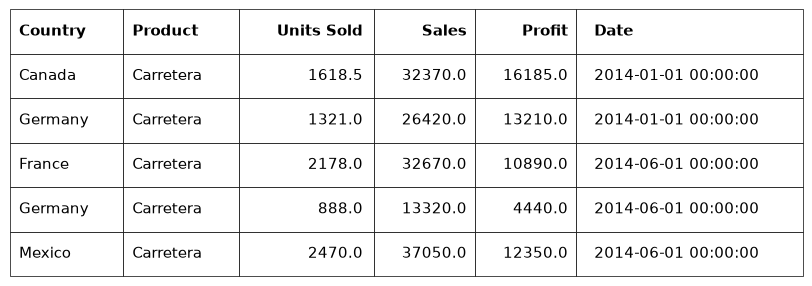

In [2]:
DATA_URL = "https://go.microsoft.com/fwlink/?LinkID=521962"
excel_path = Path("data") / "financial_sample.xlsx"
excel_path.parent.mkdir(parents=True, exist_ok=True)
if not excel_path.exists():
    with urlopen(DATA_URL, timeout=30) as response:
        excel_path.write_bytes(response.read())
    print("Downloaded Microsoft's Financial Sample workbook.")
else:
    print("Using the cached Excel workbook.")

sales = Table.from_excel(
    excel_path, sheet_name="Sheet1", usecols="B:C,E,J,L:M", parse_dates=["Date"],
)
sales.df.columns = sales.df.columns.str.strip()
assert sales.df.shape == (700, 6)
assert not sales.df.isna().any().any()
print(f"Loaded {len(sales.df):,} rows and {len(sales.df.columns)} selected columns.")
sales.show(head=5)

## Summarize with pandas

Pandas groups all observations by month and product. Dates stay as dates for the time-series chart. The report table uses readable month labels and rounded values in millions; the source measurements remain in `sales.df`. Product shares use sales, which are positive in this sample; negative or zero-total values are unsuitable for a pie chart.

In [3]:
monthly = (
    sales.df.groupby("Date", as_index=False)
    .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
    .sort_values("Date")
)
monthly["Sales (millions)"] = monthly["Sales"] / 1_000_000
product_totals = (
    sales.df.groupby("Product", as_index=False)["Sales"]
    .sum()
    .sort_values("Sales", ascending=False)
)
assert (product_totals["Sales"] > 0).all()
monthly_table = Table({
    "Month": monthly["Date"].dt.strftime("%Y-%m"),
    "Sales (millions)": monthly["Sales (millions)"].round(2),
    "Profit (millions)": (monthly["Profit"] / 1_000_000).round(2),
}, title="Monthly summary", figsize=(7, 4.8))
print(monthly_table.df.to_string(index=False))

  Month  Sales (millions)  Profit (millions)
2013-09              4.48               0.76
2013-10              9.30               1.66
2013-11              7.27               0.77
2013-12              5.37               0.69
2014-01              6.61               0.81
2014-02              7.30               1.15
2014-03              5.59               0.67
2014-04              6.96               0.93
2014-05              6.21               0.83
2014-06              9.52               1.47
2014-07              8.10               0.92
2014-08              5.86               0.79
2014-09              6.40               1.02
2014-10             12.38               1.78
2014-11              5.38               0.60
2014-12             12.00               2.03


## Line chart: sales over time

Pass a DataFrame and column names directly. Tabloom handles date values, labels, grid styling, and spacing; matplotlib keywords add markers to the monthly observations. `show()` displays inline without writing an intermediate image, and the chart remains reusable.

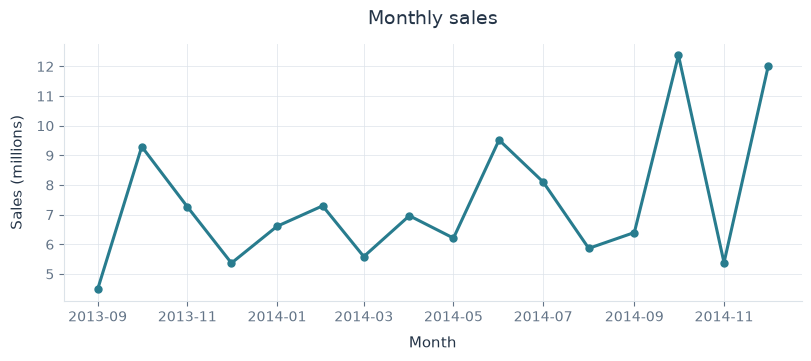

In [4]:
trend = Chart.line(
    data=monthly, x="Date", y="Sales (millions)",
    title="Monthly sales", xlabel="Month", ylabel="Sales (millions)",
    marker="o", linewidth=2.2, figsize=(8, 3.5),
)
trend.show()

## Pie chart: each product's share

`labels` can resolve a column name just like `x`. Matplotlib's `autopct` adds percentage labels. Six products make the proportions readable; a bar chart is usually clearer when there are many categories or precise comparisons matter.

The slice labels already name each product. The example uses the public `.ax` to remove the redundant legend before display.

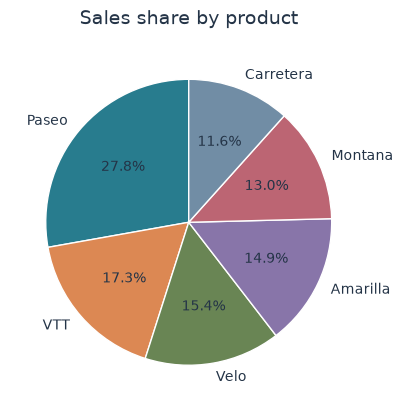

In [5]:
product_share = Chart.pie(
    data=product_totals, x="Sales", labels="Product", autopct="%1.1f%%",
    title="Sales share by product", figsize=(8, 4),
)
product_share.ax.get_legend().remove()
product_share.show()

## Export Excel data, chart images, and a PDF report

`to_excel` writes table data to a named worksheet without an index; it does not export the graphical styling. Read the exported workbook back to check the round trip. `Chart.save` exports the rendered visuals.

The PDF reuses the displayed charts. The line fills the printable width; the pie uses 60% width so both flow after the introductory text on one page. An explicit page break places the monthly summary on its own page; long tables can paginate automatically. No manual figure cleanup is required.

In [6]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
summary_path = output_dir / "monthly_summary.xlsx"
monthly_table.to_excel(summary_path, sheet_name="Monthly summary")
reloaded = Table.from_excel(summary_path, sheet_name="Monthly summary")
assert reloaded.df.equals(monthly_table.df)

trend.save(output_dir / "monthly_sales.png", dpi=160)
product_share.save(output_dir / "product_share.png", dpi=160)
report = Report("Excel Sales Report")
report.add_text(
    "Microsoft Financial Sample: 700 rows, summarized by month and product. "
    "Source: Microsoft Learn, Financial Sample Excel workbook. "
    "Amounts are sample values; this is a learning example.",
    font_size=10, space_after=8,
)
report.add_chart(trend).add_chart(product_share, resize=0.6)
report.add_page_break().add_text(
    "Monthly totals are rounded to two decimals in millions for presentation.",
    font_size=10,
).add_table(monthly_table)
report_path = output_dir / "excel_sales_report.pdf"
report.save(report_path)
print(f"Saved {summary_path} and {report_path}, plus two PNG charts.")

Saved outputs/monthly_summary.xlsx and outputs/excel_sales_report.pdf, plus two PNG charts.
